# $d_{\rm eff}$ diagnostics (loader-only)

Reads the CSVs that `deff_diagnostics/deff_latest_run_check.py` writes to
`deff_diagnostics/results/` (`deff_summary_<tag>.csv` + `deff_points_<tag>.csv`)
and plots them. No d_eff compute here — that lives in the JZ script.

Switch runs by changing `TAG` below.  Current loaded set: `reg1e-4_seed*_neg` =
5-seed noL6psi_noSm30 reg1e-4 runs (nt 60000, n1 8500, L_6<0 Θ_reg, lam 1e-3).
When the final runs land, bump `TAG` to e.g. `final_seed*_neg` and re-run.

In [1]:
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path().resolve()                            # turbulence/
RES = root.parent / 'deff_diagnostics' / 'results'
TAG = 'final_seed*_lam0.0005'                         # glob into deff_summary_<TAG>.csv
LABEL = 'turbulence_final, lam 5e-4, L_6 free (seeds 900/901/903/904/905)'
A, B = 64, 256                                      # n_mc small / large (must match the JZ run)

summ = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(RES / f'deff_summary_{TAG}.csv')))], ignore_index=True)
pts  = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(RES / f'deff_points_{TAG}.csv')))],  ignore_index=True)
assert len(summ) and len(pts), f'no CSVs matched {TAG} under {RES}'
print(f'summary: {len(summ)} rows ({summ.seed.nunique()} seeds x {summ.t.nunique()} nodes), tau in '
      f'[{summ.tau.min():.1e}, {summ.tau.max():.1e}]')
print(f'points:  {len(pts)} rows ({pts.seed.nunique()} seeds x {pts.t.nunique()} nodes x {pts.point.nunique()} points)')
print(pts.category.value_counts().to_dict())

summary: 775 rows (5 seeds x 155 nodes), tau in [6.2e-09, 1.4e+06]
points:  31000 rows (5 seeds x 155 nodes x 40 points)
{'typical': 15500, 'rare': 15500}


## 1. Denoiser $d_{\rm eff}(x,\tau)$: typical vs rare
The denoiser form is unbiased and quiet across seeds — primary estimator.

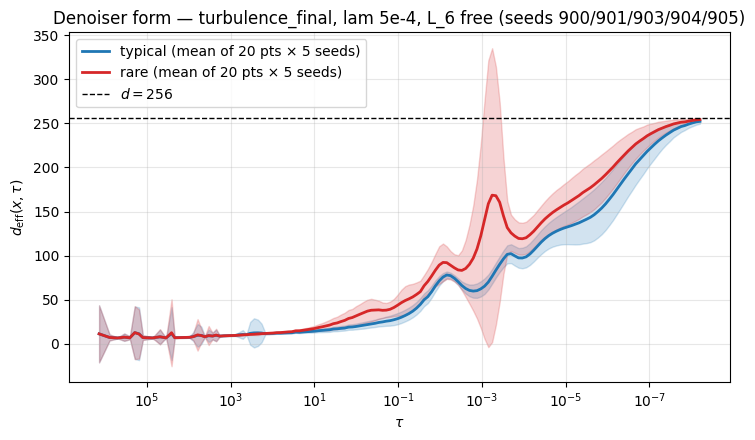

In [2]:
col_den = f'den64_{B}'       # new (float64 contraction, n_mc 256)
d_amb   = 256                 # ambient dimension (turbulence M=256, 1 channel)
mean_cat = (pts.groupby(['category', 'tau'])[col_den].mean().unstack(0).sort_index())
sd_cat   = (pts.groupby(['category', 'tau'])[col_den].std(ddof=1).unstack(0).sort_index())

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cat, c in {'typical': 'tab:blue', 'rare': 'tab:red'}.items():
    ax.plot(mean_cat.index, mean_cat[cat], color=c, lw=2, label=f'{cat} (mean of 20 pts × 5 seeds)')
    ax.fill_between(mean_cat.index, mean_cat[cat] - sd_cat[cat], mean_cat[cat] + sd_cat[cat],
                    color=c, alpha=0.2)
ax.axhline(d_amb, color='k', ls='--', lw=1, label=f'$d = {d_amb}$')
ax.set_xscale('log'); ax.invert_xaxis()
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$d_{\rm eff}(x, \tau)$')
ax.set_title(f'Denoiser form — {LABEL}')
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

## 2. Energy form vs denoiser: the four variants at $n_{\rm mc} = 256$
Two $\log Z$ constructions (bound from `h_bound_at`, Theta_reg from `h_from_theta_reg`)
× two noise schemes (fresh per node, common across nodes).  Each panel shows
mean over points of the gap $d_{\rm eff}^{\rm energy} - d_{\rm eff}^{\rm denoiser}$,
with the band = spread of the gap across evaluation points.

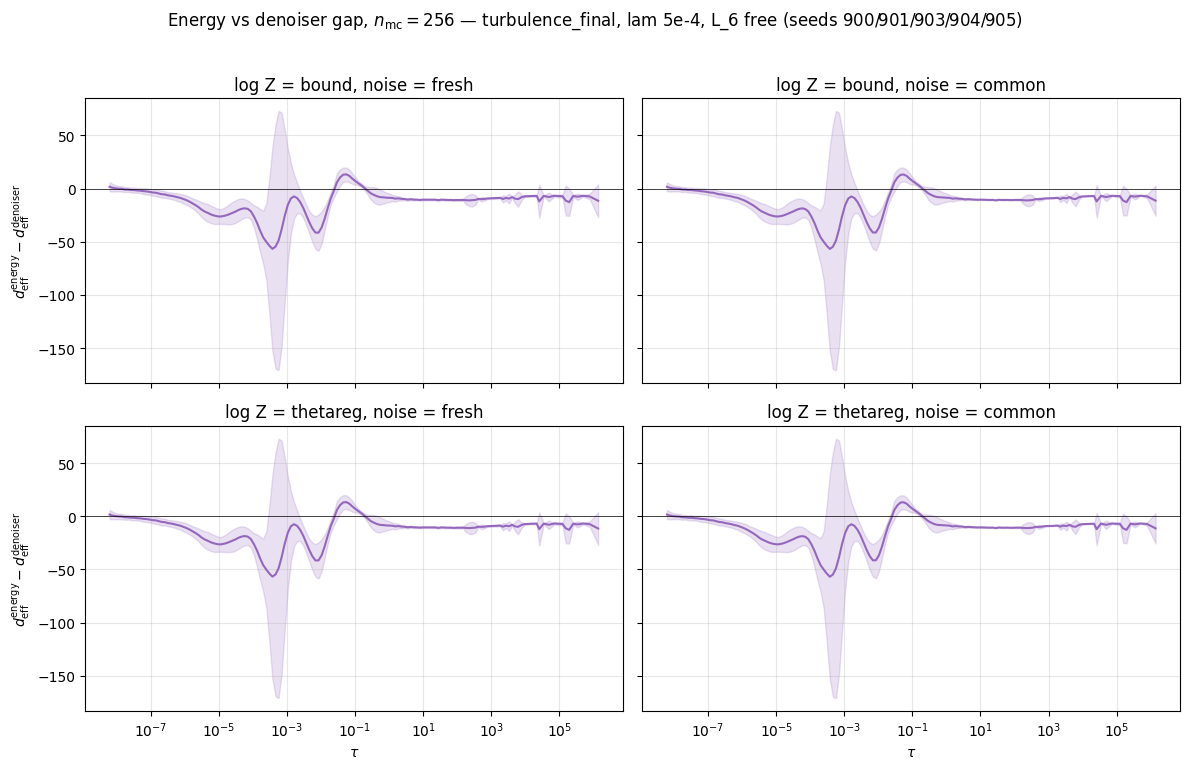

In [3]:
variants = [('bound', 'fresh'), ('bound', 'common'), ('thetareg', 'fresh'), ('thetareg', 'common')]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, (lz, nz) in zip(axes.ravel(), variants):
    key = f'gap_{lz}_{nz}_{B}'
    gm = summ.groupby('tau')[f'{key}_mean'].mean().sort_index()
    gs = summ.groupby('tau')[f'{key}_sdx'].mean().sort_index()
    ax.plot(gm.index, gm.values, color='tab:purple', lw=1.5)
    ax.fill_between(gm.index, gm - gs, gm + gs, color='tab:purple', alpha=0.2)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.invert_xaxis()
    ax.set_title(f'log Z = {lz}, noise = {nz}')
    ax.grid(alpha=0.3)
for ax in axes[-1]: ax.set_xlabel(r'$\tau$')
for ax in axes[:, 0]: ax.set_ylabel(r'$d_{\rm eff}^{\rm energy} - d_{\rm eff}^{\rm denoiser}$')
fig.suptitle(f'Energy vs denoiser gap, $n_{{\\rm mc}} = {B}$ — {LABEL}', y=1.02)
fig.tight_layout(); plt.show()

## 3. Noise reduction: fresh vs common noise
If common noise is a true win, the SD of the per-point gap should fall when
going fresh → common, especially where the denoiser curve is flat (large $\tau$).

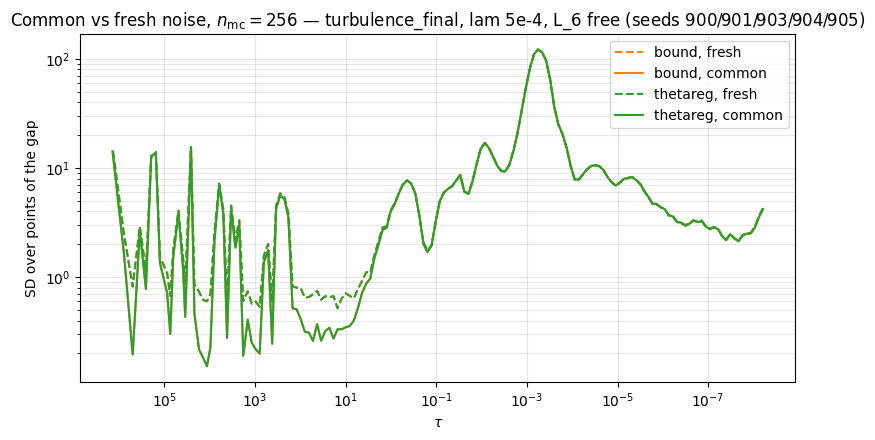

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for lz, c in [('bound', 'tab:orange'), ('thetareg', 'tab:green')]:
    f = summ.groupby('tau')[f'gap_{lz}_fresh_{B}_sdx'].mean().sort_index()
    k = summ.groupby('tau')[f'gap_{lz}_common_{B}_sdx'].mean().sort_index()
    ax.plot(f.index, f.values, '--', color=c, label=f'{lz}, fresh')
    ax.plot(k.index, k.values, '-',  color=c, label=f'{lz}, common')
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ax.set_xlabel(r'$\tau$'); ax.set_ylabel('SD over points of the gap')
ax.set_title(f'Common vs fresh noise, $n_{{\\rm mc}} = {B}$ — {LABEL}')
ax.legend(); ax.grid(alpha=0.3, which='both'); fig.tight_layout(); plt.show()

## 4. Across-seed spread of a point's $d_{\rm eff}$
What a single rare/typical plot really tells us depends on this quantity.  For
each (point, $\tau$) we take the SD of $d_{\rm eff}$ across the 5 seeds, then
its median over (point, $\tau$).  Lower = cleaner estimator.

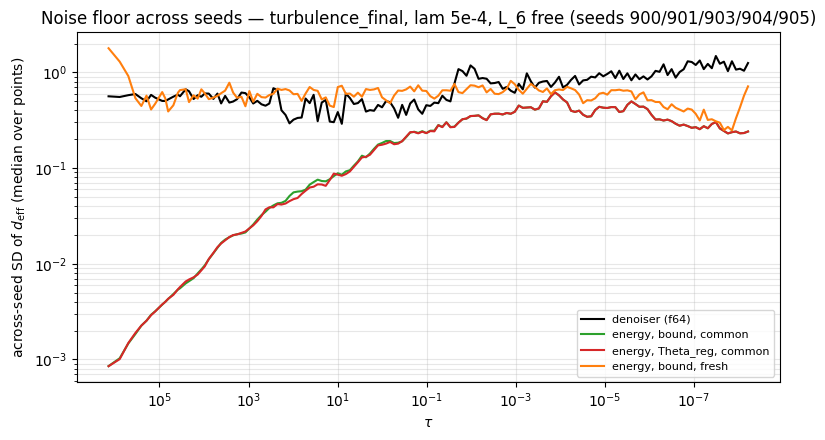

In [5]:
def seed_sd(col):
    return pts.groupby(['point', 't'])[col].std(ddof=1)

cols = {f'den64_{B}': 'denoiser (f64)',
        f'en_bound_common_{B}': 'energy, bound, common',
        f'en_thetareg_common_{B}': 'energy, Theta_reg, common',
        f'en_bound_fresh_{B}': 'energy, bound, fresh'}
sd_df = pd.DataFrame({label: seed_sd(c) for c, label in cols.items()})
sd_df['tau'] = pts.groupby(['point', 't']).tau.first()

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, c in zip(cols.values(), ['black', 'tab:green', 'tab:red', 'tab:orange']):
    m = sd_df.groupby('tau')[name].median().sort_index()
    ax.plot(m.index, m.values, label=name, color=c)
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ax.set_xlabel(r'$\tau$'); ax.set_ylabel('across-seed SD of $d_{\\rm eff}$ (median over points)')
ax.set_title(f'Noise floor across seeds — {LABEL}')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both'); fig.tight_layout(); plt.show()

## 5. Precision check: float32 vs float64 denoiser
The script keeps a float32 denoiser run (`den32_{B}`) alongside the float64 default.
`den32_minus_64` in the summary is the per-node median of $|{\rm den}_{32} - {\rm den}_{64}|$
over points.  Compare to `den_mc_sd` = the MC noise of the denoiser itself.

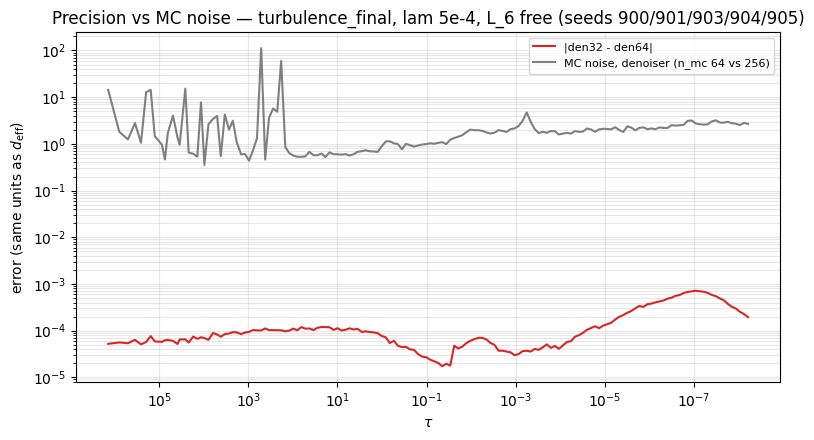

In [6]:
p = summ.groupby('tau')[['den32_minus_64', 'den_mc_sd']].mean().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p.index, p['den32_minus_64'], label='|den32 - den64|', color='tab:red')
ax.plot(p.index, p['den_mc_sd'], label=f'MC noise, denoiser (n_mc {A} vs {B})', color='tab:gray')
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ax.set_xlabel(r'$\tau$'); ax.set_ylabel('error (same units as $d_{\\rm eff}$)')
ax.set_title(f'Precision vs MC noise — {LABEL}')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both'); fig.tight_layout(); plt.show()

## 6. $\log Z$ construction: predicted shift vs observed
The two $\log Z$ versions can only differ by an $x$-independent shift, equal to
$-d(\delta \log Z)/ds$.  The script predicts this shift directly from the two
integrals (no d_eff involved) — compare it to the actual mean-over-points gap
difference between the two variants.

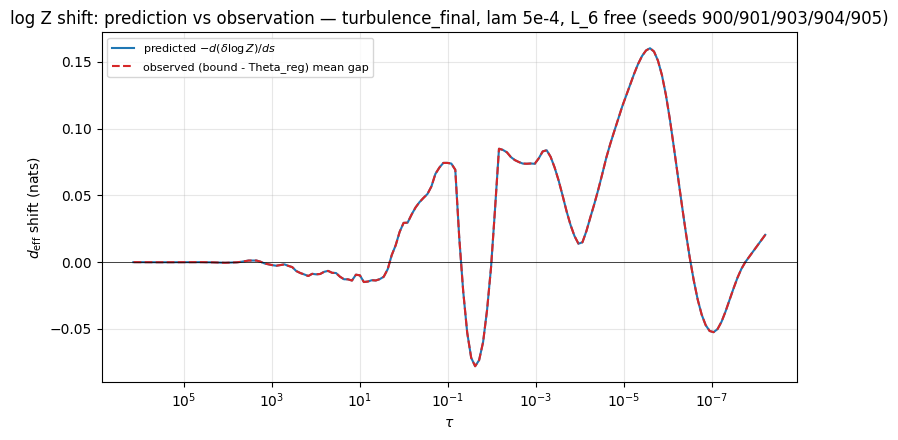

In [7]:
obs = (summ.groupby('tau')[f'gap_bound_common_{B}_mean'].mean()
       - summ.groupby('tau')[f'gap_thetareg_common_{B}_mean'].mean()).sort_index()
pred = summ.groupby('tau').pred_logZ_shift.mean().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pred.index, pred.values, color='tab:blue', label=r'predicted $-d(\delta \log Z)/ds$')
ax.plot(obs.index, obs.values, '--', color='tab:red', label='observed (bound - Theta_reg) mean gap')
ax.axhline(0, color='k', lw=0.5)
ax.set_xscale('log'); ax.invert_xaxis()
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$d_{\rm eff}$ shift (nats)')
ax.set_title(f'log Z shift: prediction vs observation — {LABEL}')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

## 7. The energy residual itself (quantitative)
Takeaway table: for the quietest energy variant (common noise, large $n_{\rm mc}$),
the gap decomposes into an $x$-independent shift (the $\log Z$ choice) and a
signed, seed-stable residual (the heat-equation mismatch of MGD's $p_\theta$).

In [8]:
bands = [(1e2, np.inf), (1, 1e2), (1e-2, 1), (1e-4, 1e-2), (1e-6, 1e-4), (0, 1e-6)]
pts['band'] = pd.cut(pts.tau, [-np.inf] + [lo for lo, _ in bands][::-1] + [np.inf], right=False)
rows = []
for lo, hi in bands:
    mk = (summ.tau >= lo) & (summ.tau < hi)
    if not mk.any(): continue
    row = dict(tau_band=f'[{lo:g}, {hi:g})', n_nodes=int(mk.sum()),
               den=summ.loc[mk, 'den_mean'].median(),
               shift_pred=summ.loc[mk, 'pred_logZ_shift'].median(),
               gap_bound=summ.loc[mk, f'gap_bound_common_{B}_mean'].median(),
               gap_thetareg=summ.loc[mk, f'gap_thetareg_common_{B}_mean'].median(),
               gap_sd_pts=summ.loc[mk, f'gap_bound_common_{B}_sdx'].median())
    rows.append(row)
tbl = pd.DataFrame(rows)
print(LABEL)
print(tbl.to_string(index=False, float_format=lambda v: f'{v:.3g}'))

turbulence_final, lam 5e-4, L_6 free (seeds 900/901/903/904/905)
       tau_band  n_nodes  den  shift_pred  gap_bound  gap_thetareg  gap_sd_pts
     [100, inf)      205 8.06   -7.06e-05      -8.01         -8.01        0.22
       [1, 100)      115 15.9      -0.007      -10.4         -10.4       0.388
      [0.01, 1)      110 37.4      0.0371      -1.97            -2        6.15
 [0.0001, 0.01)      110 97.2      0.0739      -35.1         -35.1        20.7
[1e-06, 0.0001)      110  145       0.121      -21.4         -21.5        7.64
     [0, 1e-06)      125  233    -0.00506      -2.81         -2.76        2.83
